In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
# from cobos.tokens import ibm_token, group_instance, group_instance2
from fradm.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

first_layout_qubit = 43
eplg_absolute = 1e-2

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Auxiliary lattice plot

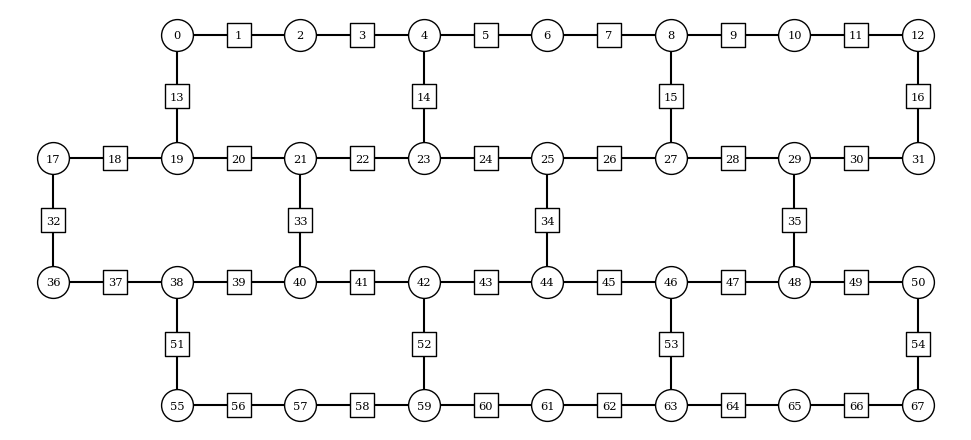

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 3

HeavyHexLattice(plaquette_width, plaquette_height).plot_lattice(number_qubits=True)

# Simulation settings

In [63]:
from utils.hexec import create_estimator_options
from utils.hexec import ExecDB

lattice_dims_arr = [(3, 3)]
J_arr = [0.3]
h_arr = [0.8]
lamb_arr = [1]
g_arr = [10]

x_basis = False

fractional_gates = False

# strings_arr = [[6, 7, 8, 16, 26, 25, 24, 34, 43, 44, 45, 54, 64, 63, 62, 72, 81, 82, 83, 92, 102, 101, 100]]
strings_arr = [[4, 14, 24, 34, 45, 53, 63]]
string_arr_tr = [9, 15, 26, 34, 43, 52, 58]

string_arr_mg = [4, 14, 23, 24, 25, 34, 44, 45, 46, 53, 63]
string_arr_tr_mg = [10, 9, 8, 15, 27, 26, 25, 34, 44, 43, 42, 52, 59, 58, 57]
# strings_arr = [[12, 16, 30, 35, 47, 53, 64, 72, 81, 90, 98, 109, 115, 127, 131]]
# strings_arr = [[4, 14, 24]]

final_time = 5
dt = 0.2
steps = 40

max_layers = 50
adjust_depth = True

shots = 75000

odr = True
flip_threshold = None

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

# Error guarantees

In [5]:
from z2hex.geometry import HeavyHexLattice
from z2hex.circs import trotter_dt
import numpy as np

lattice = HeavyHexLattice(*lattice_dims_arr[0])

error_dt = trotter_dt(eplg_absolute, lattice, J_arr[0], h_arr[0], lamb_arr[0])
nsteps = np.ceil(final_time / error_dt)

print(f"With provided the hardware error Δt should be:\nΔt = {error_dt:.5f}")
print(f"To correctly reach the desired final time, the number of layers required is:\nN = {nsteps} ({nsteps*6} 2Qb depth)")

With provided the hardware error Δt should be:
Δt = 0.05465
To correctly reach the desired final time, the number of layers required is:
N = 92 (552 2Qb depth)


In [6]:
from z2hex.circs import trotter_error

lattice = HeavyHexLattice(*lattice_dims_arr[0])

settings_error = trotter_error(dt, lattice, J_arr[0], h_arr[0], lamb_arr[0])
sim_max_nlayers = np.ceil(final_time // dt).astype(int)

print(f"With the current simultation settings Δt is at most\nΔt = {dt:.5f}")
print(f"The error per layer commited in the wrost case is\nƐ = {settings_error:.05}")
print(f"The number of layers at the final evolution time is\nN = {sim_max_nlayers} ({6*sim_max_nlayers} 2Qb depth)")

With the current simultation settings Δt is at most
Δt = 0.20000
The error per layer commited in the wrost case is
Ɛ = 0.49017
The number of layers at the final evolution time is
N = 24 (144 2Qb depth)


# Circuit generation & observables

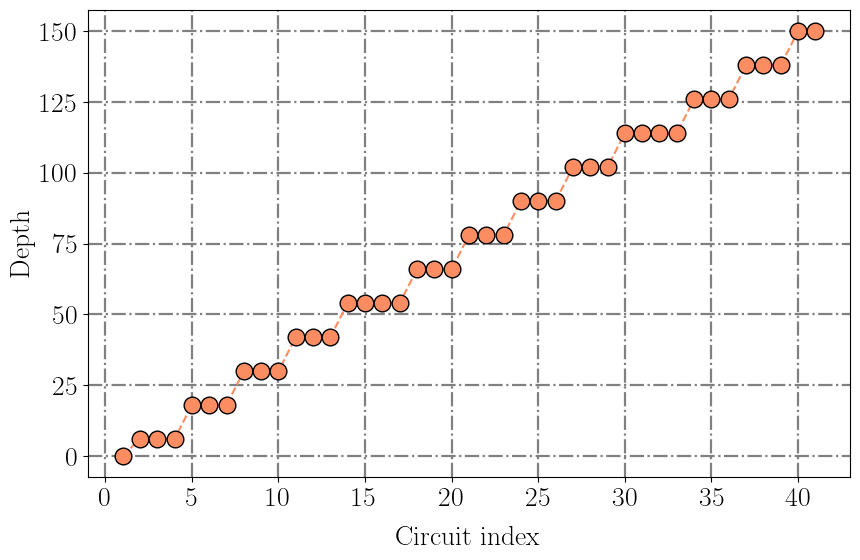

In [13]:
from z2hex.circs import string_quench_simulation_circuits_dt, odr_compuncomp_circuits_dt
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.plotting import plot_circuit_arr_depth
from utils.circs import generate_and_save_circs
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import os

optimization_level = 3

circuits = [] # circuits[dims][Jhλg][t]
if odr: odr_circuits = []
observable_generating_funcs = [] # observable_generating_funcs[dims][i]
postselection_operators_funcs = [] # postselection_operators_funcs[dims][i]
extra_options = [] # extra_options[dims][Jhλg]

for (px, py), string_arr in zip(lattice_dims_arr, strings_arr):
    this_circuits = []
    if odr: this_odr_circuits = []
    this_extra_options = []
    lattice = HeavyHexLattice(px, py)
    for J, h, lamb, g in product(J_arr, h_arr, lamb_arr, g_arr):
        circuits_filepath = os.path.join(circ_folder_path, f"z2hex_string_quench_circs_{device}_px_{px}_py_{py}_maxt_{final_time}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.qpy")
        circs_args = (lattice, J, h, lamb, string_arr, final_time, dt, steps, backend, optimization_level, g, first_layout_qubit, x_basis, True, False)
        physical_circuits = string_quench_simulation_circuits_dt(*circs_args)
        this_circuits.append(physical_circuits)
        this_extra_options.append({"backend": device, "plaquette_width": px, "plaquette_height": py, "J": J, "h": h, "λ":lamb, "g": g, "string_arr": string_arr, "final_time": final_time, "dt": dt, "steps": steps} | ({"fractional_gates": True} if fractional_gates else {}))
        if odr:
            odr_func_args = (lattice, J, h, lamb, final_time, dt, steps, backend, g, string_arr, first_layout_qubit, x_basis)
            this_odr_circuits.append(odr_compuncomp_circuits_dt(*odr_func_args))
    circuits.append(this_circuits)
    if odr: odr_circuits.append(this_odr_circuits)
    observable_generating_funcs.append([(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))])
    postselection_operators_funcs.append(lambda nqubits: postselection_operators(lattice, x_basis))
    extra_options.append(this_extra_options)

# circuits[0][0][1].draw(output="mpl", idle_wires=False)
plot_circuit_arr_depth(circuits[0][0])

# Post-selected circuit execution

### Send jobs to hardware

In [64]:
from utils.postselection import execute_postselected_sampler_batch
from itertools import product

jobs = [] # jobs[dims][Jhλg][t]

for i, (px, py) in enumerate(lattice_dims_arr):
    this_dims_jobs = []
    for Ji, hi, lambi, gi in product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr))):
        params_ind = gi + lambi*len(g_arr) + hi*len(g_arr)*len(lamb_arr) + Ji*len(g_arr)*len(lamb_arr)*len(g_arr)
        if odr:
            this_jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits[i][params_ind], postselection_operators_funcs[i], observable_generating_funcs[i], odr_circuits=odr_circuits[i][params_ind], extra_options=extra_options[i][params_ind], job_db=job_db)
        else:
            this_jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits[i][params_ind], postselection_operators_funcs[i], observable_generating_funcs[i], extra_options=extra_options[i][params_ind], job_db=job_db)
        this_dims_jobs.append(this_jobs)
    jobs.append(this_dims_jobs)

### Load jobs with the same options

In [14]:
from utils.postselection import load_postselected_jobs
from itertools import product

observables = [] # jobs[dims][Jhλg][mitig][t]
samples_dicts = [] # samples_dicts[dims][Jhλg][t]
postselected_samples_dicts = [] # postselected_samples_dicts[dims][Jhλg][t]

for i, (px, py) in enumerate(lattice_dims_arr):
    this_dims_observables = []
    this_dims_samples_dicts = []
    this_dims_postselected_samples_dicts = []
    for j, (Ji, hi, lambi, gi) in enumerate(product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr)))):
        clean_extra_options = extra_options[i][j].copy()
        if odr:
            this_observables, this_samples_dicts, this_postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits[i][j], postselection_operators_funcs[i], observable_generating_funcs[i], clean_extra_options, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_samples_dicts=True, return_postselected_samples_dicts=True, odr_circuits=odr_circuits[i][j], max_shots=shots)
        else:
            this_observables, this_samples_dicts, this_postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits[i][j], postselection_operators_funcs[i], observable_generating_funcs[i], clean_extra_options, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_samples_dicts=True, return_postselected_samples_dicts=True, max_shots=shots)
        this_dims_observables.append(this_observables)
        this_dims_samples_dicts.append(this_samples_dicts)
        this_dims_postselected_samples_dicts.append(this_postselected_samples_dicts)
    observables.append(this_dims_observables)
    samples_dicts.append(this_dims_samples_dicts)
    postselected_samples_dicts.append(this_dims_postselected_samples_dicts)

In [18]:
import numpy as np
np.asarray(observables).shape

(1, 1, 4, 41, 68)

In [113]:
def string_width(string_arr_tr, obs):
    xs = [i for i in range(-len(string_arr_tr)//2, len(string_arr_tr)+1)]
    eed_sum_lad = 0
    for x, eed_x in zip(xs, obs):
        eed_sum_lad += eed_x * ((x) ** 2)
    eed_sum_lad = eed_sum_lad / sum(obs)
    return eed_sum_lad

def plot_average_separated(obs, ax, string):

    times = range(np.asarray(obs).T.shape[0])
    matter_occupation_matrix = (1 - np.asarray(obs).T[:, 0::2])/2
    gauge_z_matrix = np.asarray(obs).T[:, 1::2]

    if string == "transverse":
        marker = "p"
    elif string == "longitudinal":
        marker = "^"
    av_occ = np.mean(matter_occupation_matrix, axis=1)
    av_gf = np.mean(gauge_z_matrix, axis=1)
    ax[0].plot(times, av_occ, marker, label=f"{string}")
    ax[0].set_ylabel(r"$(1 - \langle Z \rangle)/2$", labelpad=10)
    ax[0].set_xlabel(r"Matter sites")
    ax[1].plot(times, av_gf, marker, label=f"{string}")
    ax[1].set_ylabel(r"$\langle Z \rangle$", labelpad=10)
    ax[1].set_xlabel(r"Gauge sites")

import matplotlib.pyplot as plt
from z2chain.plotting import x_t_plot, x_t_separated_plot

def plot_string_observables( 
                            observable: np.ndarray, 
                            transverse: list=None, 
                            longitudinal: list=None,
                            cm: bool=False,
                            separated: bool=True,
                            sim_type: int=0,
                            obs_type: str="occ",
                            params: list=None,
                            std: np.ndarray=None

                            ):
    """
    plot string observables

    This function plots the values of the gauge fields <Z> or 
    the matter sites occupation (1 - <Z>)/2 for the qubits 
    longitudinal and/or transversal to the string.
    If both components are passed it plots the normalized averages of the
    observables in one plot. If cm (colormap) is true it returns two colormaps.
    These functionalities could be used to identify different physics modes 
    given by the time evolution.

    observable: np.ndarray - total array of observables
    transverse: list - list of qubit labels according to the layout chosen. By default None
    longitudinal: list - list of qubit labels according to the layout chosen. By default None
    cm: bool - colormap with every local observables. By default False, will plot averages
    sim_type: int - type of simulation chosen. Choose among: 0 - real, 1 - no odr, 
            2 - calibration circs odr, 3 - raw. By default 0
    obs_type: str - type of observable to plot. Choose among: "occ" occupation and "gf" gauge field. By default occupation
    params: list - parameters used during the time evolution. By default None
    std: np.ndarray - standard deviation of the observables. By default None

    """
    obs_t = None
    obs_l = None
    
    plt.rc("text", usetex=True)
    plt.rc("font", size=24, family="serif", weight="bold")
    plt.rc("figure", dpi=300)
    
    times = range(observable.shape[1])
    if separated:
        if transverse is not None:
            obs_t = [observable[sim_type,:,i] for i in transverse]
        if longitudinal is not None:
            obs_l = [observable[sim_type,:,i] for i in longitudinal]

        if cm:
            if obs_t is not None:
                print(f"\n -- tranverse:")
                x_t_separated_plot(np.asarray(obs_t).T)
            if obs_l is not None:
                print(f"\n -- longitudinal:")
                x_t_separated_plot(np.asarray(obs_l).T)
        
        else:
            fig, ax = plt.subplots(1, 2, figsize=[12, 8], sharey=True, dpi=300)

            if obs_t is not None:
                plot_average_separated(obs_t, ax, "transverse")
            if obs_l is not None:
                plot_average_separated(obs_l, ax, "longitudinal")

            
            ax[0].legend(fontsize=12)
            ax[1].legend(fontsize=12)
            ax[0].grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
            ax[1].grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
            plt.suptitle("Matter $\&$ Gauge sites of the transverse and longitudinal strings")
            plt.show()
            
    else:
        if obs_type == "occ":
            observable = (1 - observable[:,:]) / 2

        if transverse is not None:
            obs_t = [observable[sim_type,:,i] for i in transverse]
        if longitudinal is not None:
            obs_l = [observable[sim_type,:,i] for i in longitudinal]
            
        if cm:
            if obs_t is not None:
                print(f"\n -- tranverse:")
                x_t_plot(np.asarray(obs_t).T)
            if obs_l is not None:
                print(f"\n -- longitudinal:")
                x_t_plot(np.asarray(obs_l).T)

        else:
            if obs_t is not None:
                av_obs_t = np.mean(obs_t, axis=0)
                plt.plot(times, av_obs_t, 'p', label="Transverse")
            if obs_l is not None:
                av_obs_l = np.mean(obs_l, axis=0)
                plt.plot(times, av_obs_l, '^', label="Longitudinal")
            
            plt.title("Gauge sites of the transverse and longitudinal strings")
            plt.xlabel("Circuit index")
            plt.ylabel("$\\frac{1}{N}\\sum_{x} \\langle Z(x) \\rangle$")
            plt.legend(fontsize=12)
            plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
            plt.show()

<>:98: SyntaxWarning: invalid escape sequence '\&'
<>:98: SyntaxWarning: invalid escape sequence '\&'
/var/folders/32/fk_0xqj113d4fp2cxfpqtfd40000gr/T/ipykernel_74781/1181636751.py:98: SyntaxWarning: invalid escape sequence '\&'
  plt.suptitle("Matter $\&$ Gauge sites of the transverse and longitudinal strings")



 -- tranverse:


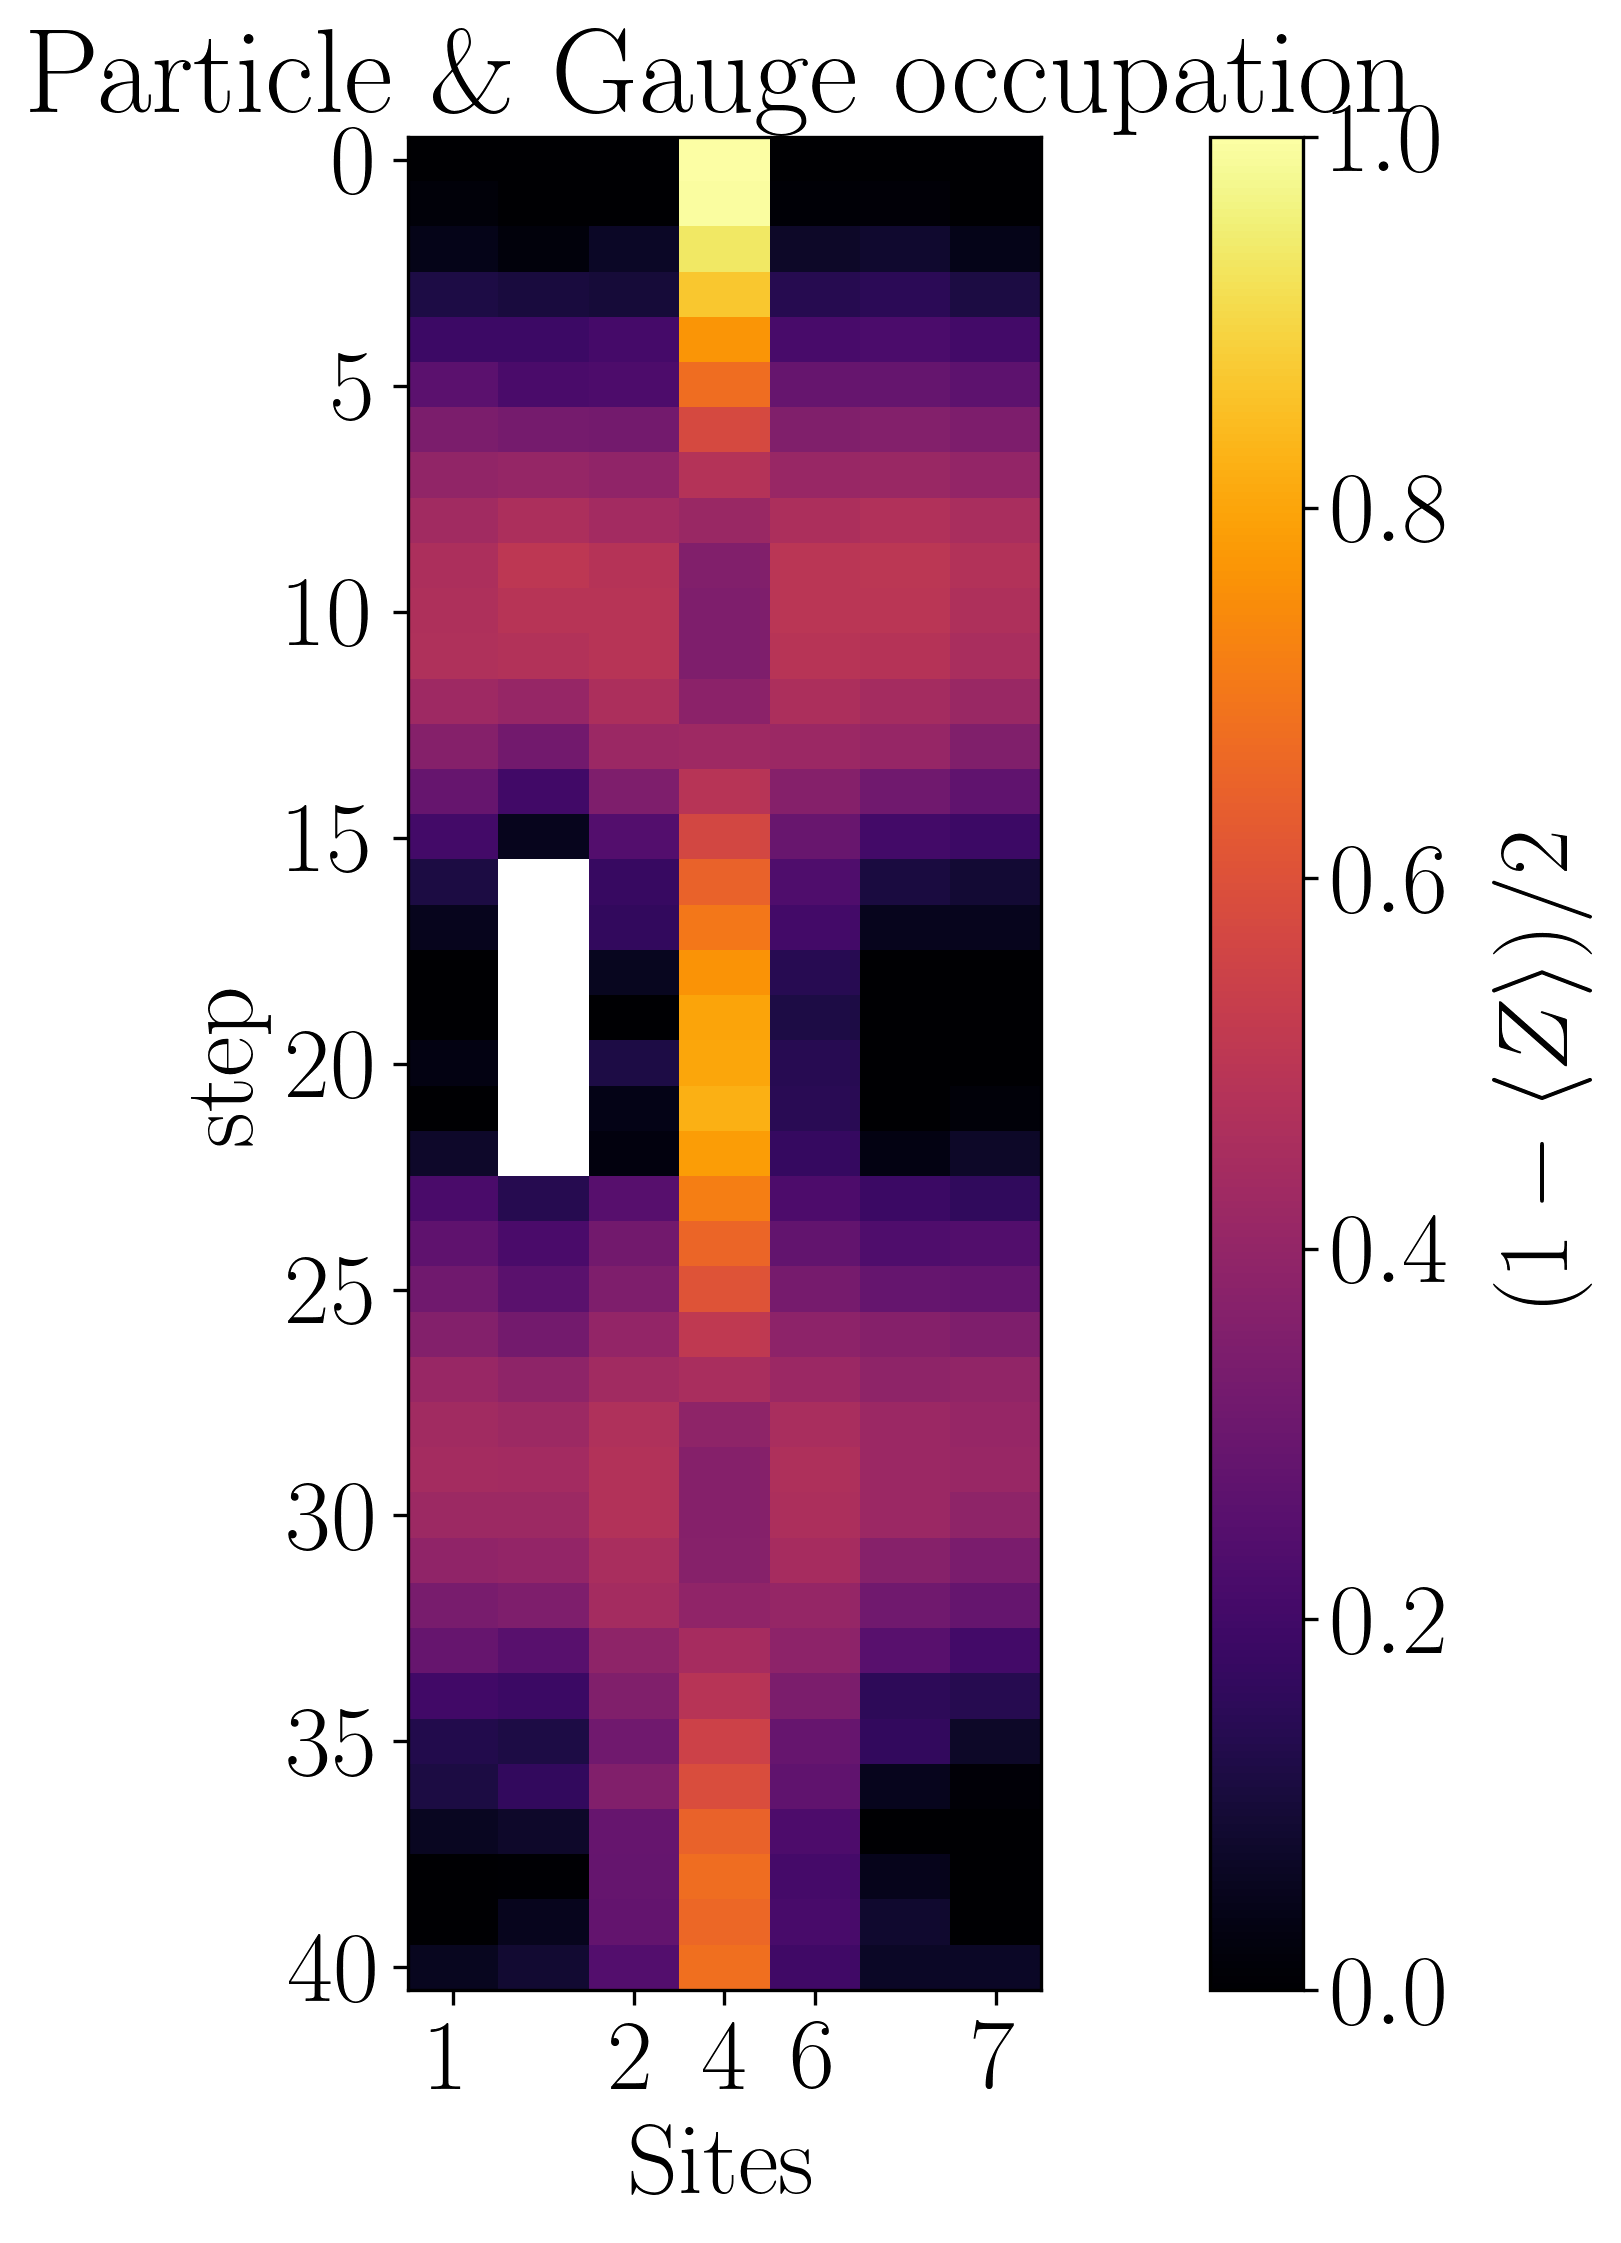


 -- longitudinal:


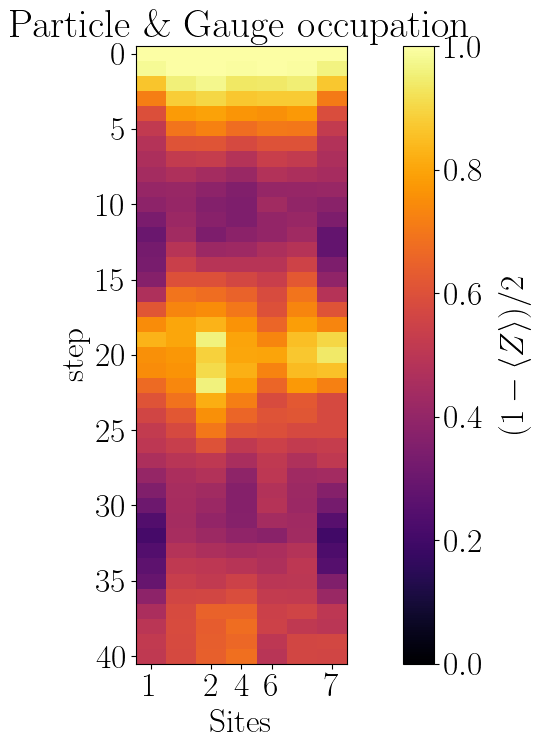

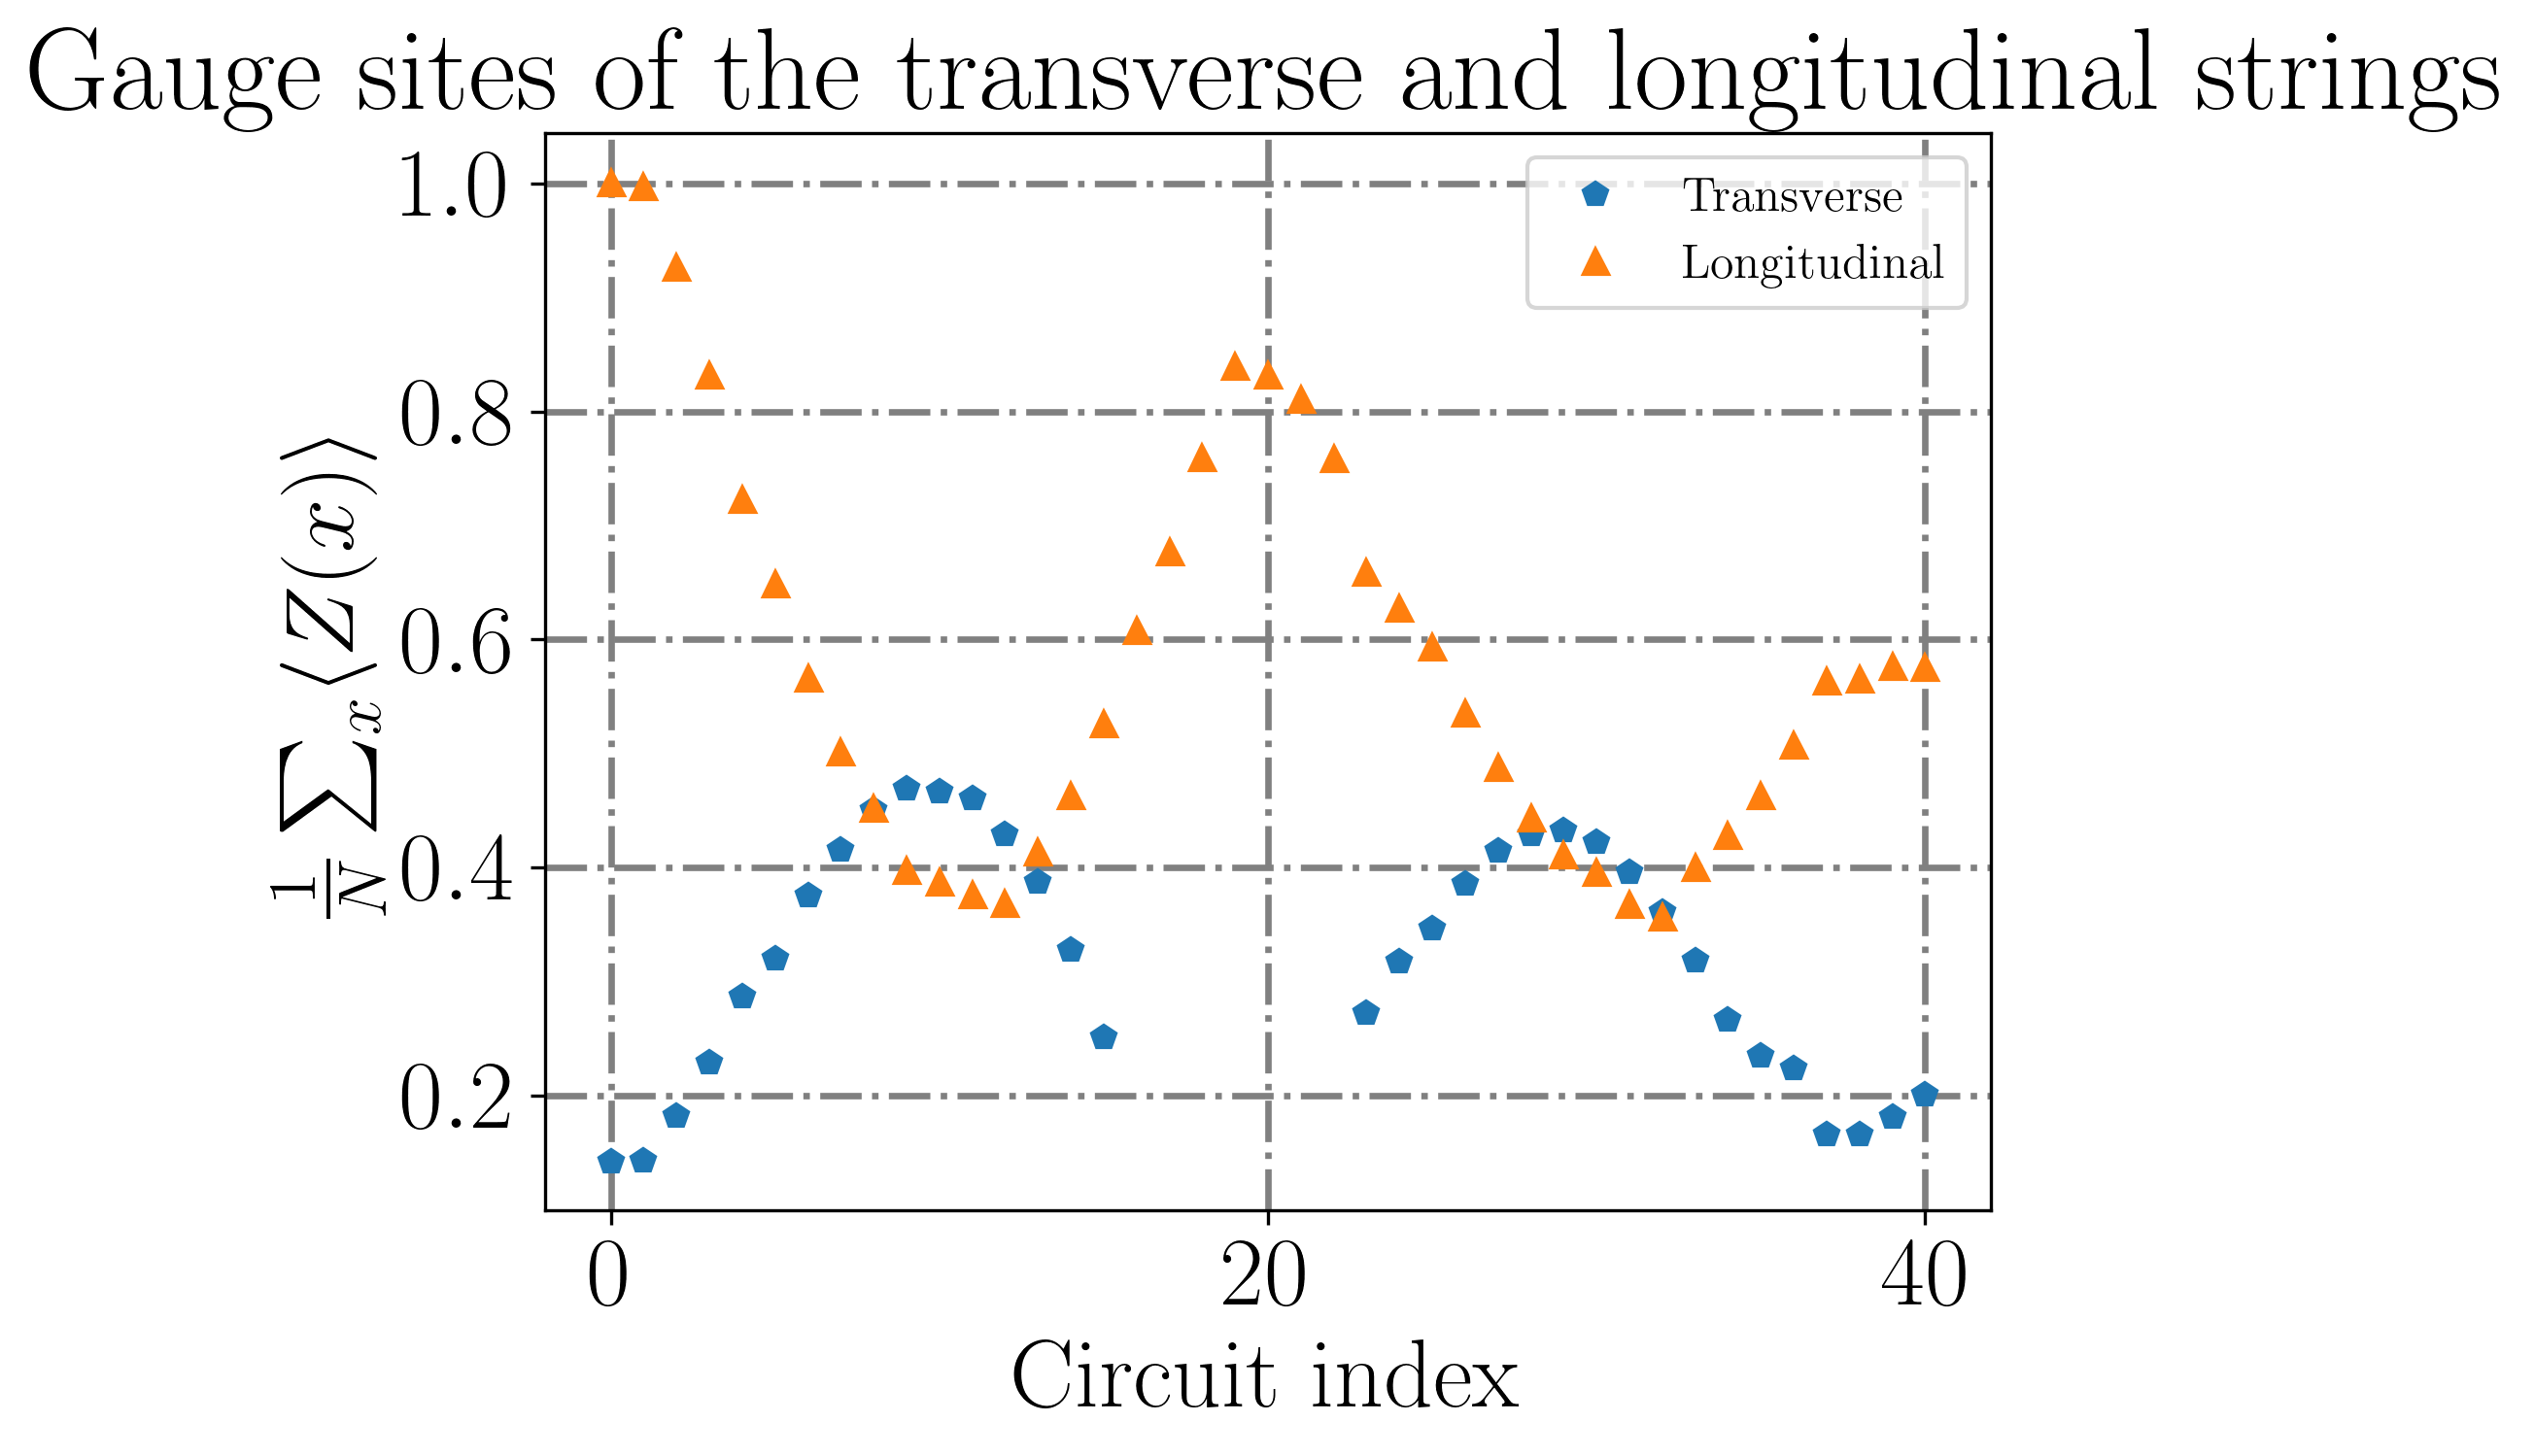


 -- tranverse:


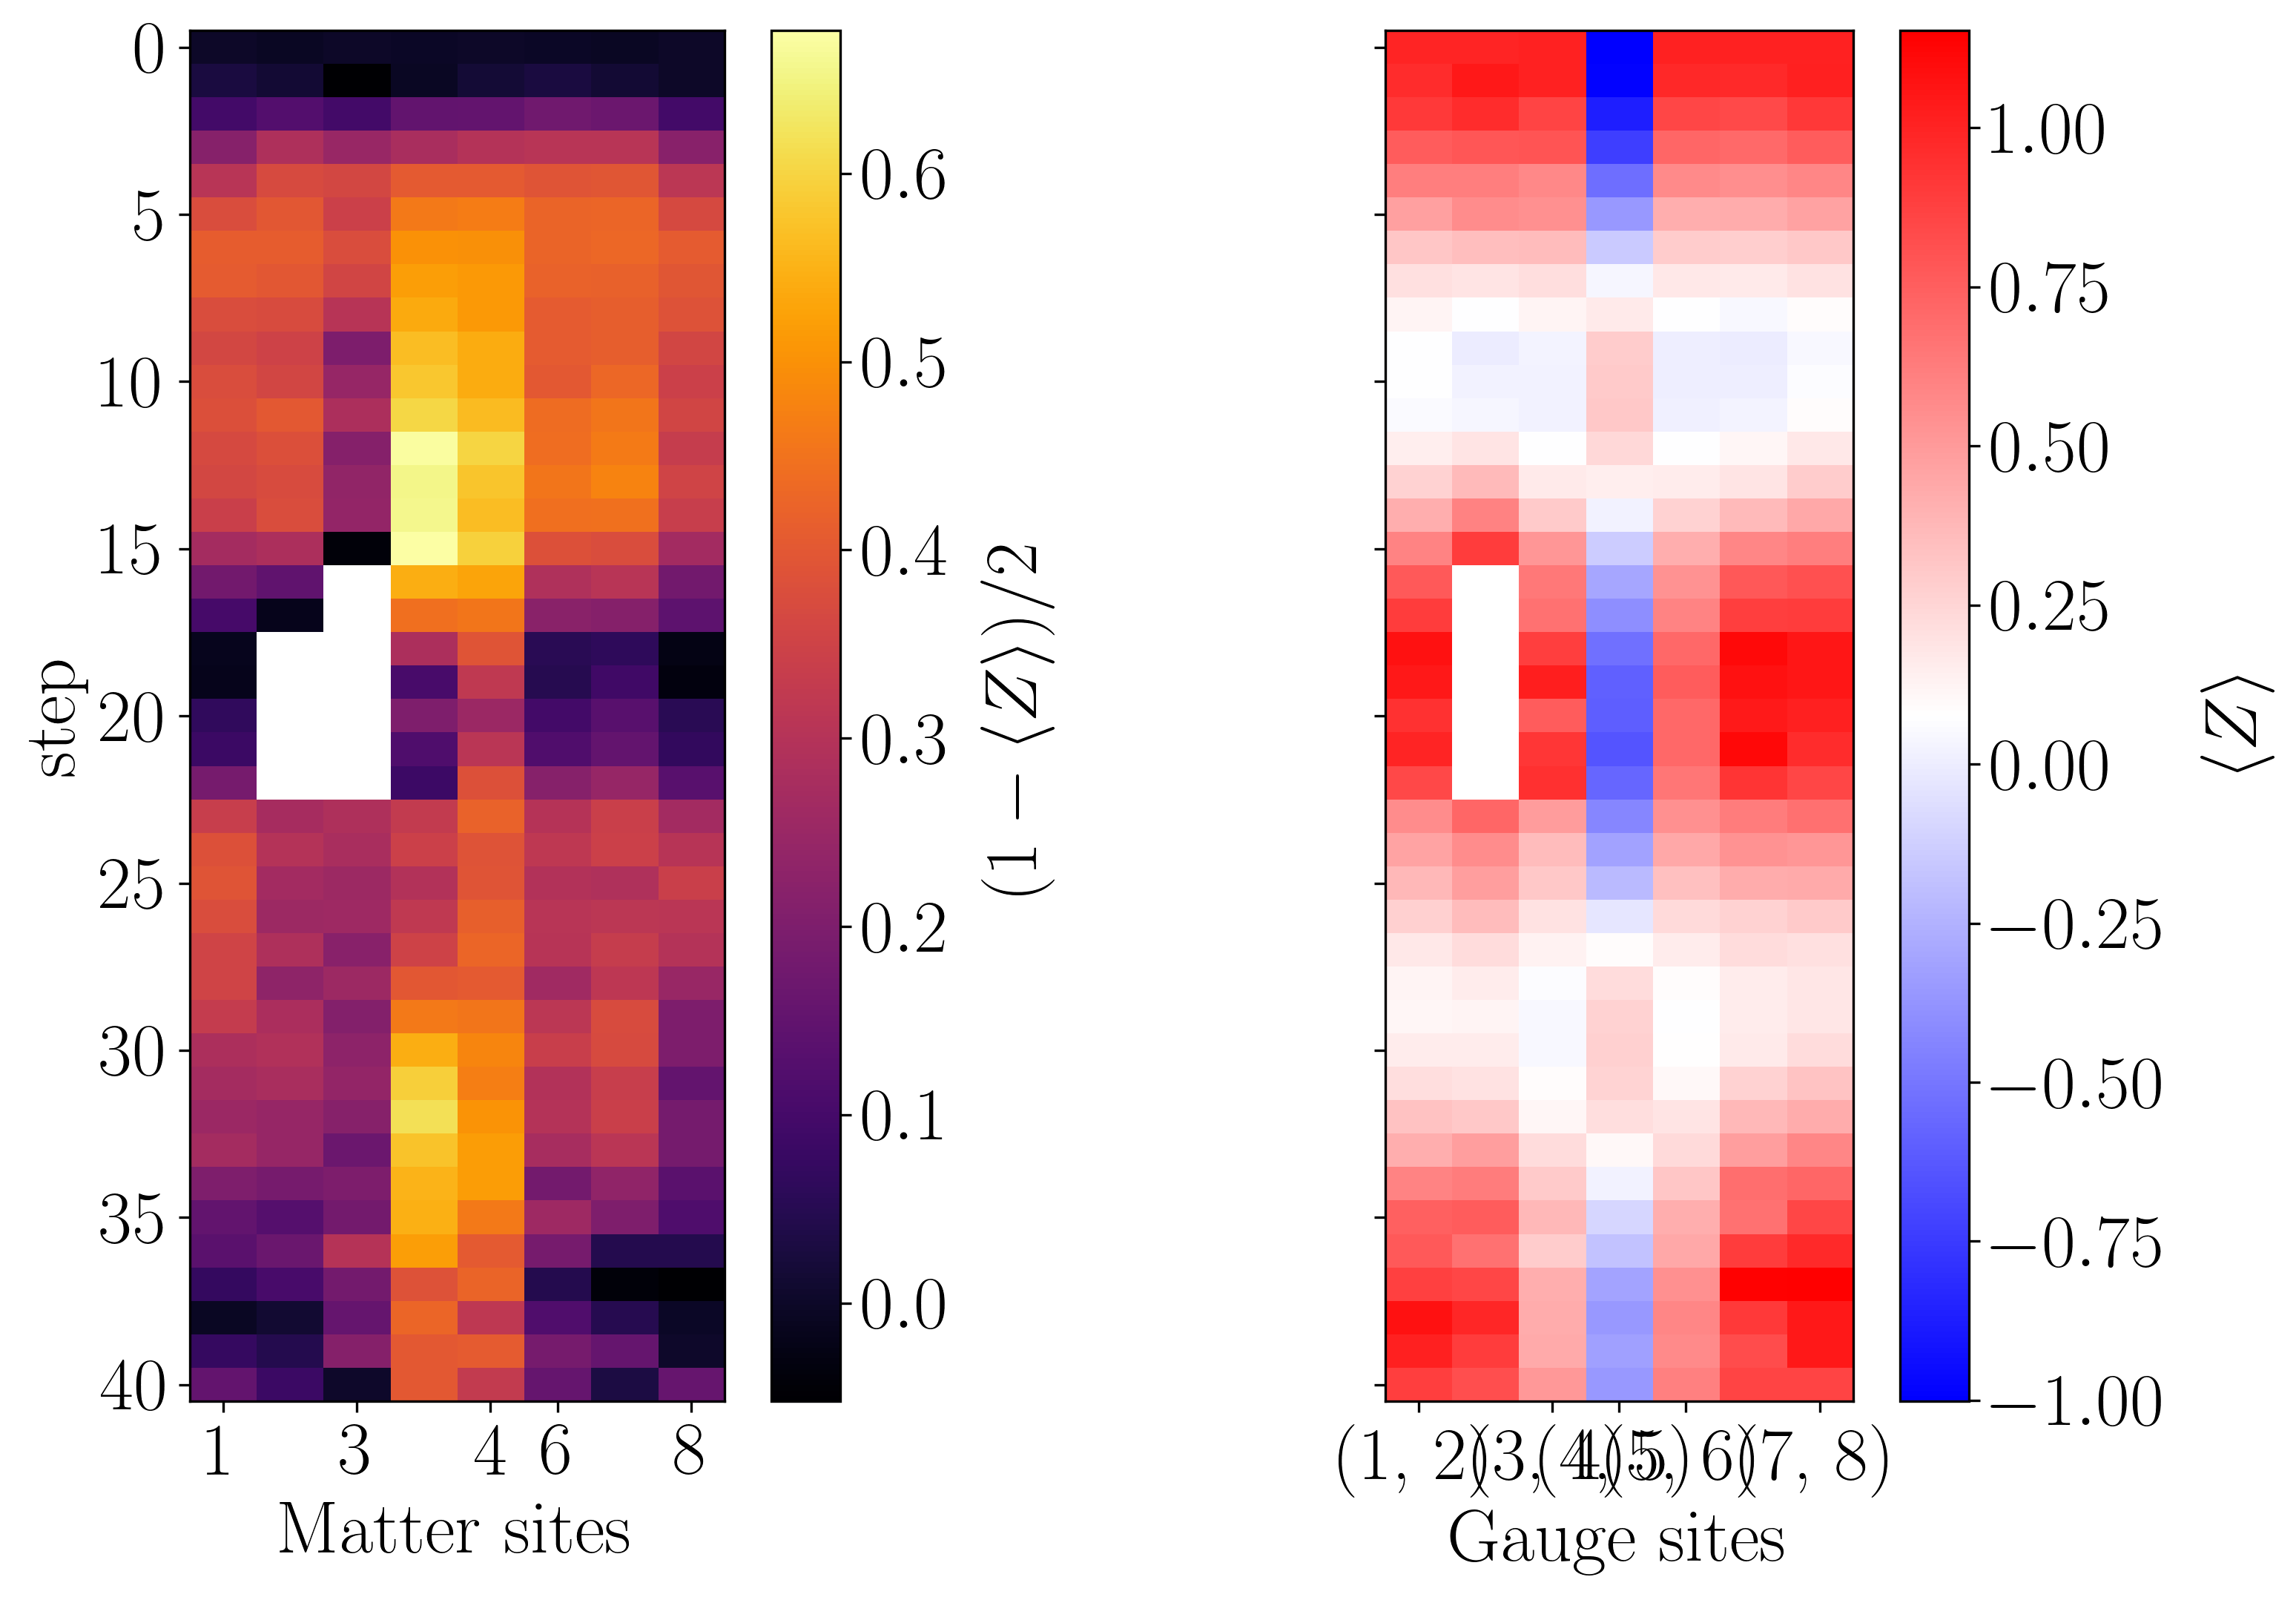


 -- longitudinal:


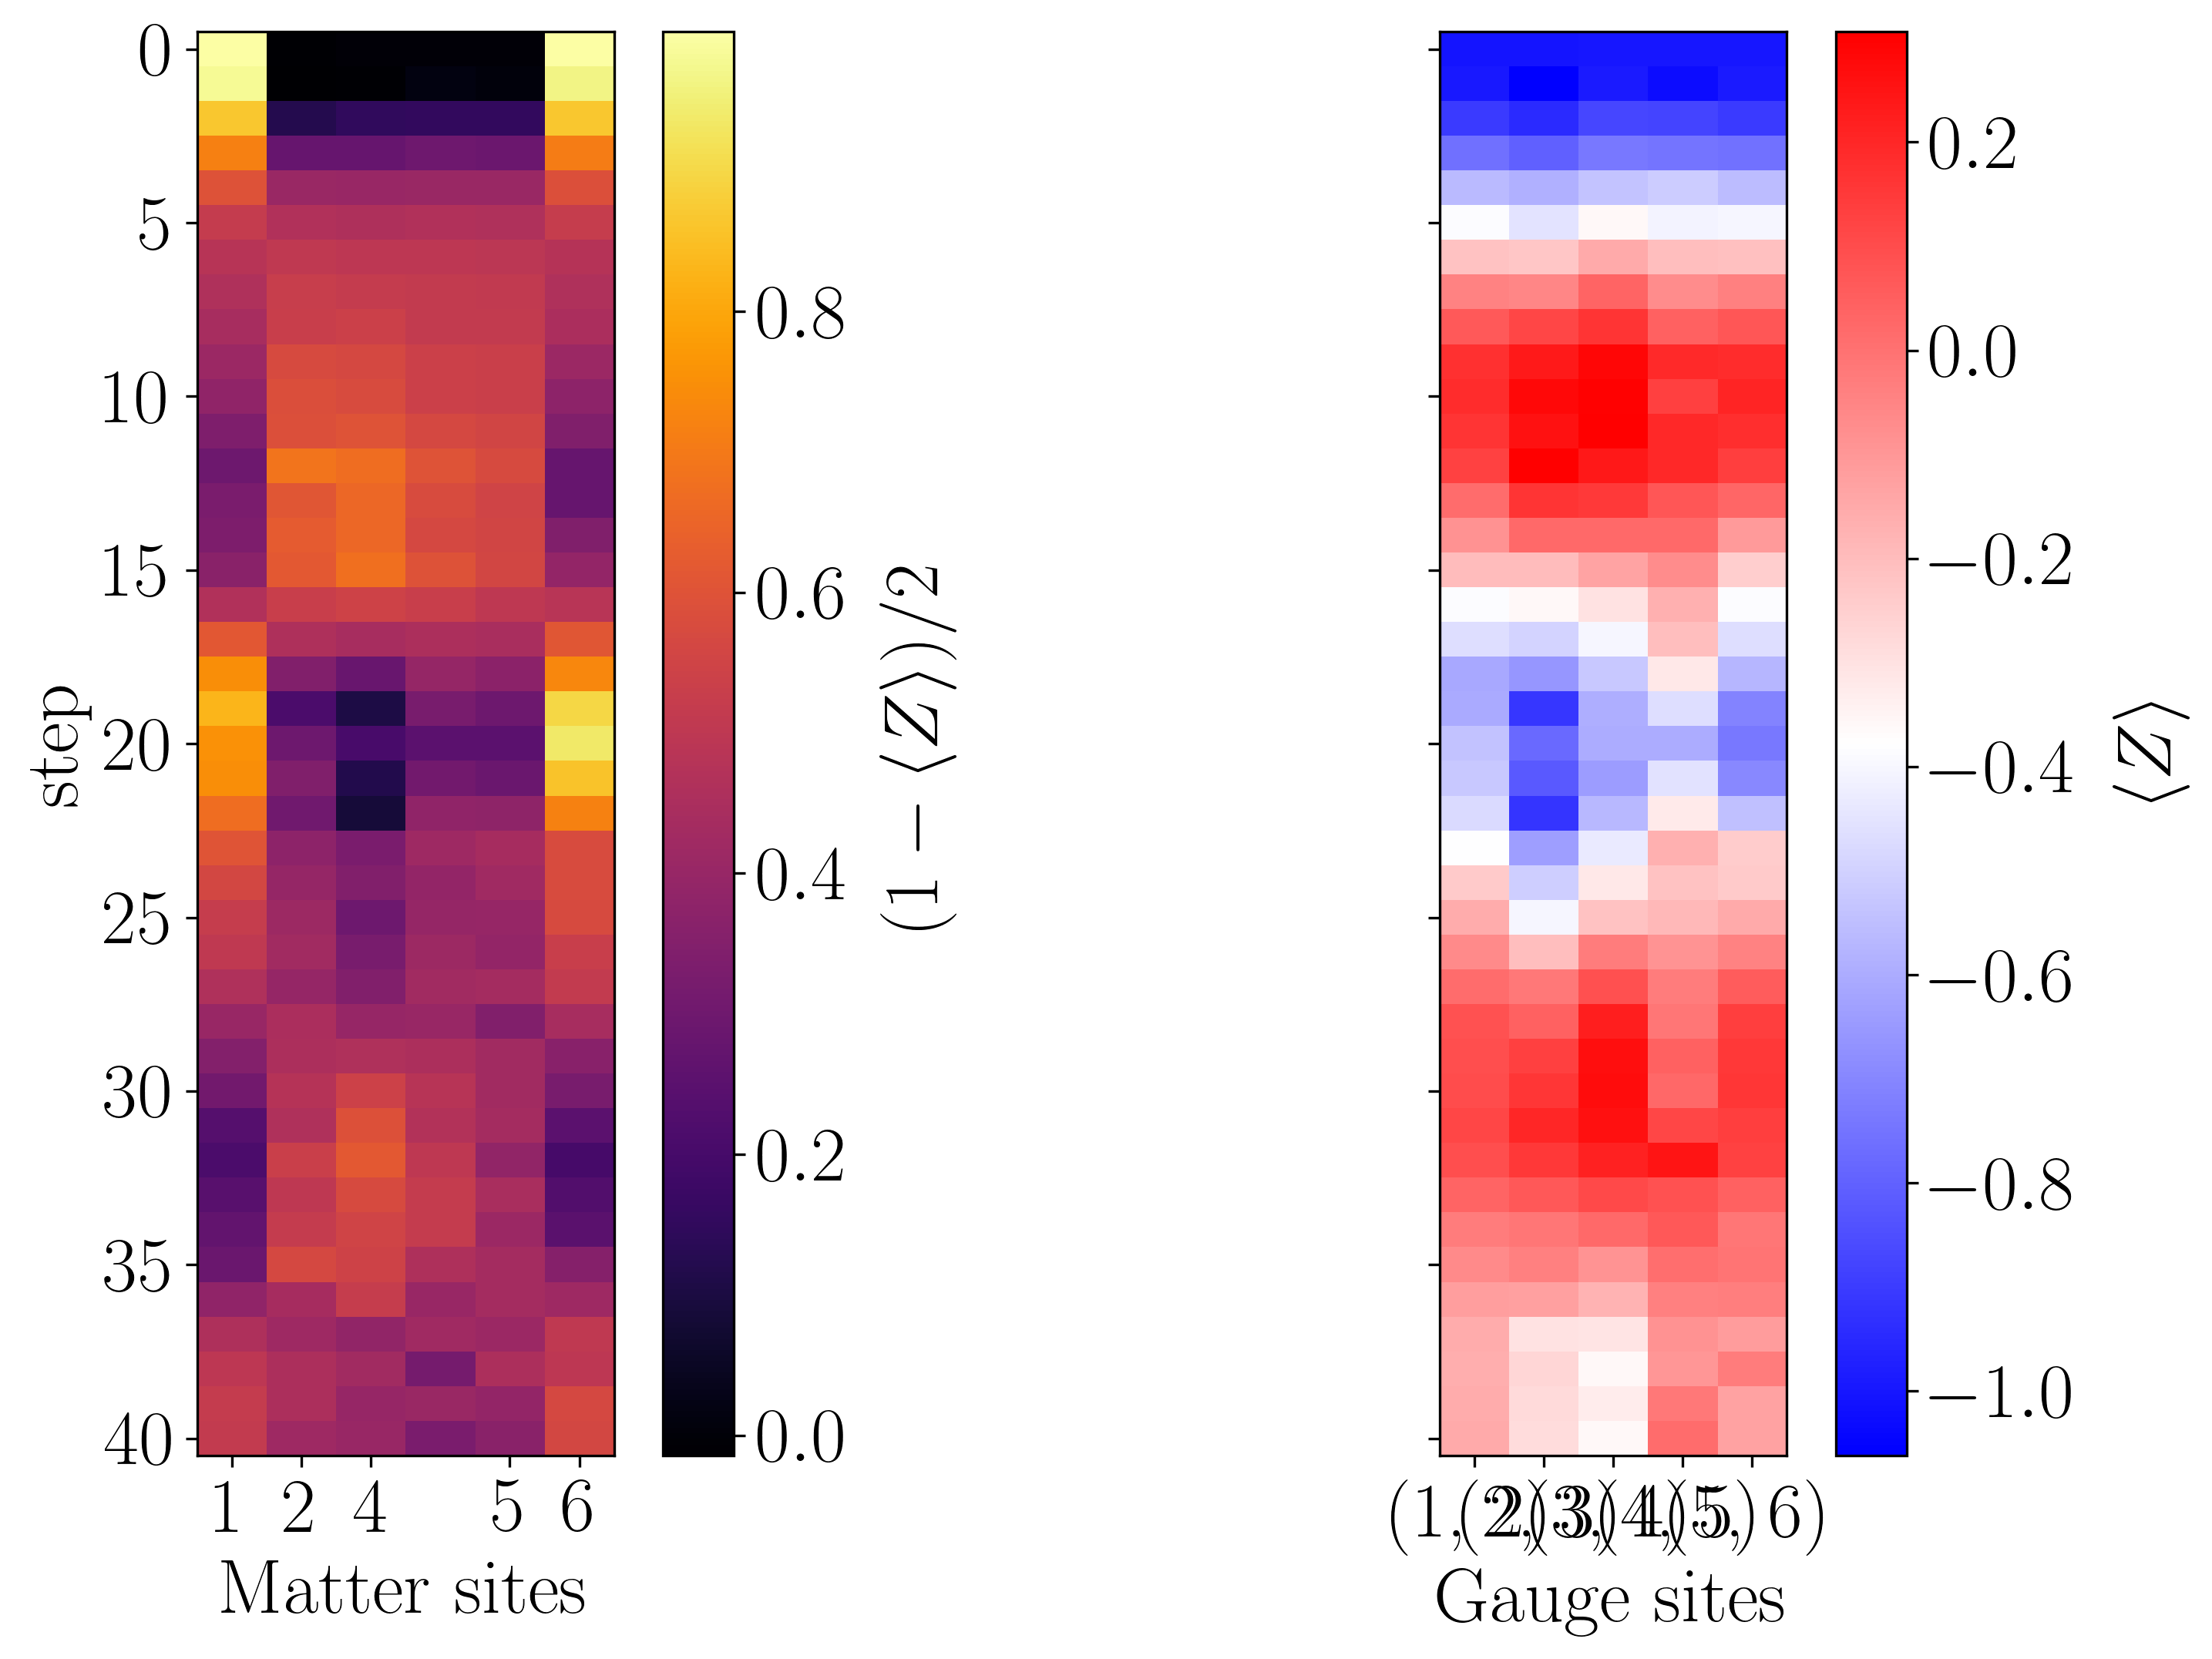

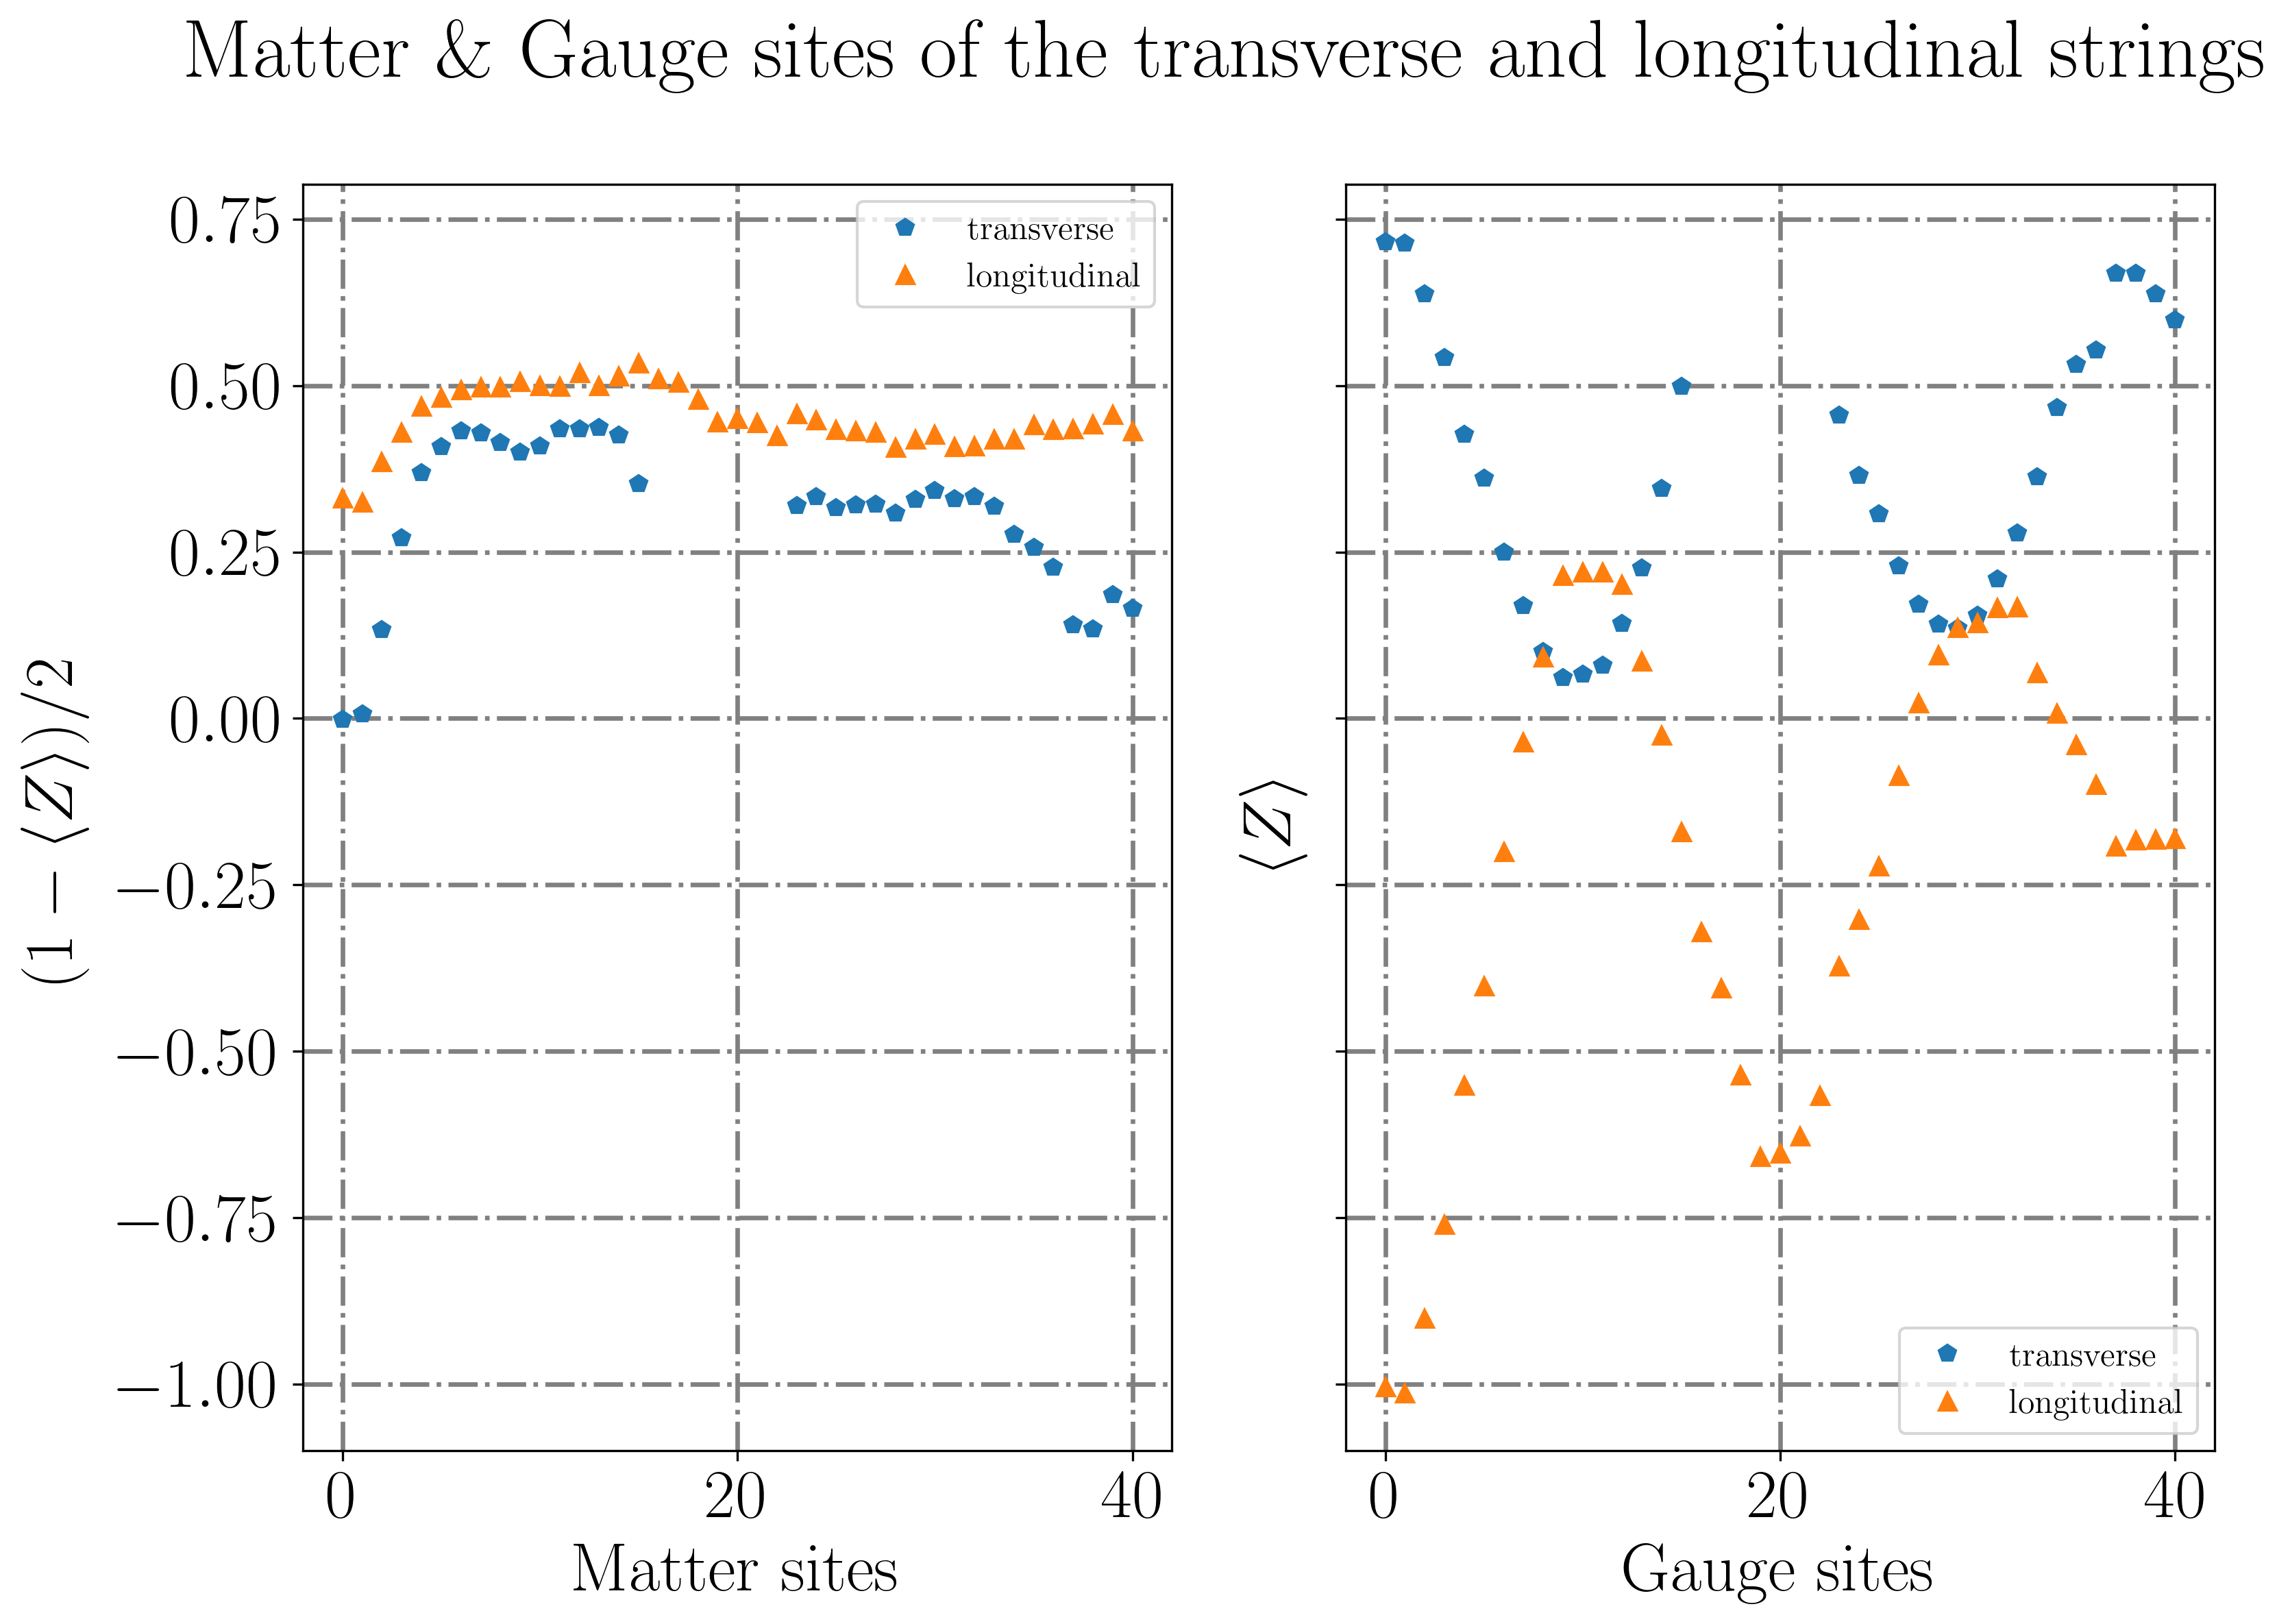

In [114]:
plot_string_observables(np.asarray(observables)[0,0], longitudinal=string_arr, transverse=string_arr_tr, cm=True, separated=False)
plot_string_observables(np.asarray(observables)[0,0], longitudinal=string_arr, transverse=string_arr_tr, cm=False, separated=False)
plot_string_observables(np.asarray(observables)[0,0], longitudinal=string_arr_mg, transverse=string_arr_tr_mg, cm=True)
plot_string_observables(np.asarray(observables)[0,0], longitudinal=string_arr_mg, transverse=string_arr_tr_mg, cm=False)

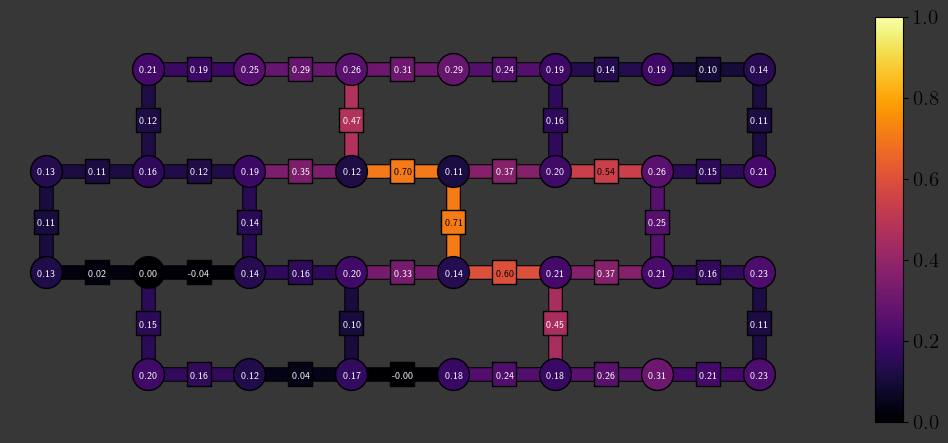

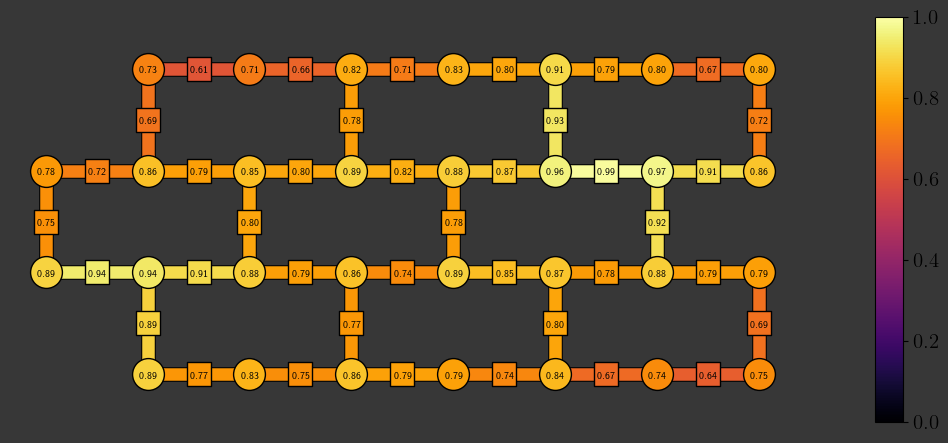

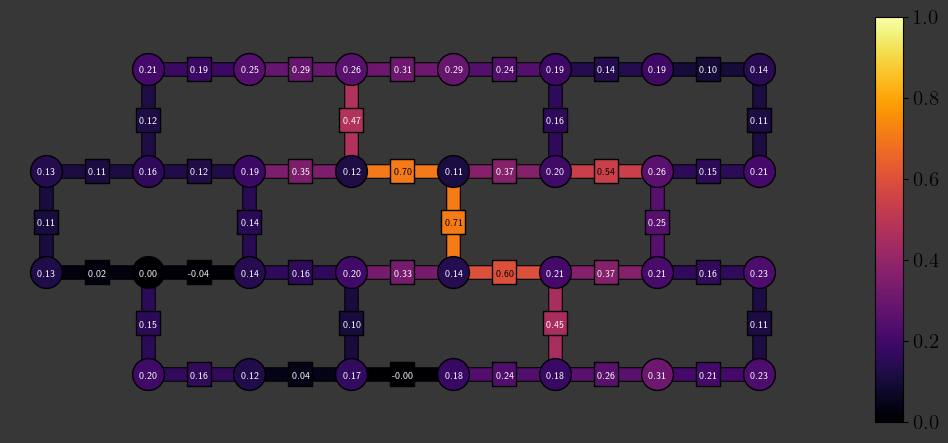

In [10]:
from utils.postselection import initialize_postselection, measure_diagonal_observables, get_recovered_postselected_samples_dict
from z2hex.plotting import local_observable_plot
import utils.odr as odr

job_index = 35

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_funcs[i], observable_generating_funcs[i])

samples = samples_dicts[0][0][0][job_index]
odrsamples = samples_dicts[0][0][1][job_index]
psamples_manual = get_recovered_postselected_samples_dict(samples, postselection_ops, circuits[0][0][job_index].layout.final_index_layout()[::-1], flip_threshold=flip_threshold)
psamples = postselected_samples_dicts[0][0][0][job_index]
podrsamples = get_recovered_postselected_samples_dict(odrsamples, postselection_ops, circuits[0][0][job_index].layout.final_index_layout()[::-1], flip_threshold=flip_threshold)
pobservables = measure_diagonal_observables(podrsamples, diagonal_observables, circuits[0][0][job_index].layout.final_index_layout())[::-1]
podrprob = odr.compute_depolarizing_probability(pobservables, 1, 0, odr_circuits[0][0][job_index].num_qubits)
finalobs = odr.renormalize_observable(observables[0][0][1][job_index], podrprob, 0, circuits[0][0][job_index].num_qubits, [-1, 1])

local_observable_plot((1-observables[0][0][0][job_index])/2, lattice, cmap_range=[0, 1], dark_theme=True)
local_observable_plot(podrprob, lattice, cmap_range=[0, 1], dark_theme=True)
local_observable_plot((1-finalobs)/2, lattice, cmap_range=[0, 1], dark_theme=True)

# Plots

In [9]:
from z2hex.plotting import local_obs_anim

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

for i, (px, py) in enumerate(lattice_dims_arr):
    for j, (Ji, Hi, lambi, gi) in enumerate(product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr)))):
        postselected_odr_filepath = f"z2hex_string_quench_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        postselected_filepath = f"z2hex_string_quench_nodr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        odr_filepath = f"z2hex_string_quench_odr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        raw_filepath = f"z2hex_string_quench_raw_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        local_obs_anim((1 - observables[i][j][0])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_odr_filepath)
        local_obs_anim((1 - observables[i][j][1])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_filepath)
        local_obs_anim((1 - observables[i][j][2])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=odr_filepath)
        local_obs_anim((1 - observables[i][j][3])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=raw_filepath)

ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.4)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1_3 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

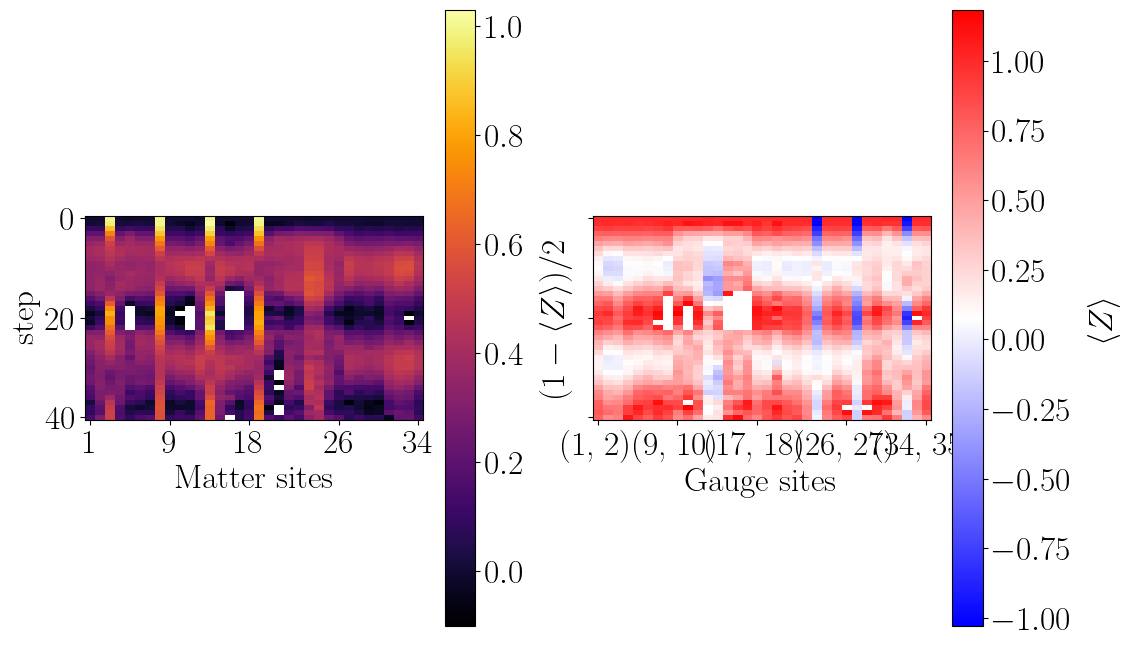

In [10]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observables[i][j][0])